# Car price prediction project - Suprevised lerning(regression)

In [1]:
#importation 

In [2]:
# Data manupuliation
import pandas as pd
import numpy as np

# Data Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning 
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Lasso #models LinearRegression & Lasso(adds regularization to prevent overfitting from escal)
from sklearn.ensemble import RandomForestRegressor # model random forest
from sklearn import metrics # for evaluate

#Saving the model
import joblib
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')

In [3]:
df = pd.read_csv('car_data.csv')
df.head(10) #selling price is target value 

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0
5,vitara brezza,2018,9.25,9.83,2071,Diesel,Dealer,Manual,0
6,ciaz,2015,6.75,8.12,18796,Petrol,Dealer,Manual,0
7,s cross,2015,6.50,8.61,33429,Diesel,Dealer,Manual,0
8,ciaz,2016,8.75,8.89,20273,Diesel,Dealer,Manual,0
9,ciaz,2015,7.45,8.92,42367,Diesel,Dealer,Manual,0


In [4]:
df.shape

(301, 9)

In [5]:
df.info() # mix of num n categories

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Seller_Type    301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB


In [6]:
df.isnull().sum() # no nan

Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64

In [7]:
df.describe()

,Year,Selling_Price,Present_Price,Kms_Driven,Owner
count,301.000000,301.000000,301.000000,301.000000,301.000000
mean,2013.627907,4.661296,7.628472,36947.205980,0.043189
std,2.891554,5.082812,8.644115,38886.883882,0.247915
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.900000,1.200000,15000.000000,0.000000
50%,2014.000000,3.600000,6.400000,32000.000000,0.000000
75%,2016.000000,6.000000,9.900000,48767.000000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000


In [8]:
print('\nFuel Type:')
print(df['Fuel_Type'].value_counts())

print('\nSeller Type:')
print(df['Seller_Type'].value_counts())

print('\nTransmission:')
print(df['Transmission'].value_counts())

print('\nOwner:')
print(df['Owner'].value_counts())


Fuel Type:
Fuel_Type
Petrol    239
Diesel     60
CNG         2
Name: count, dtype: int64

Seller Type:
Seller_Type
Dealer        195
Individual    106
Name: count, dtype: int64

Transmission:
Transmission
Manual       261
Automatic     40
Name: count, dtype: int64

Owner:
Owner
0    290
1     10
3      1
Name: count, dtype: int64


In [9]:
# visualise dataset 

Text(0.5, 1.0, 'Distribution of Car Selling Prices')

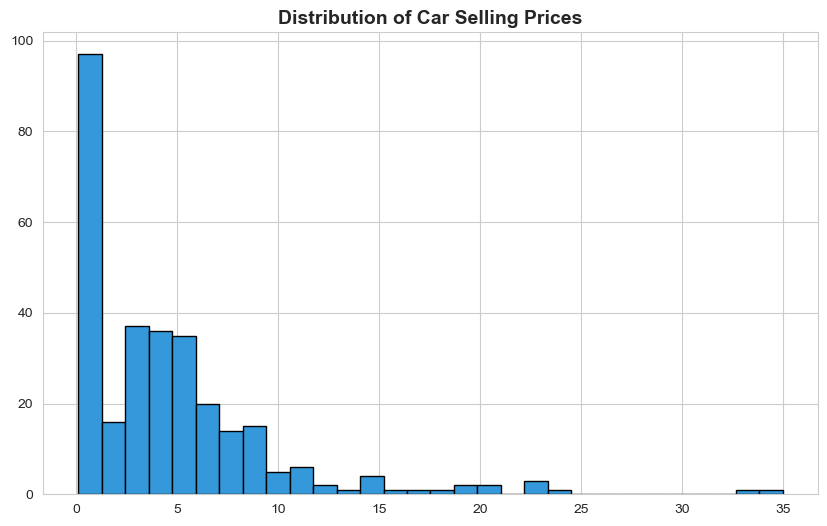

In [12]:
plt.figure(figsize=(10, 6))
plt.hist(df['Selling_Price'], bins=30, color='#3498db', edgecolor='black')
plt.title('Distribution of Car Selling Prices', fontsize=14, fontweight='bold')

Text(0.5, 1.0, 'Feature Correlation Heatmap')

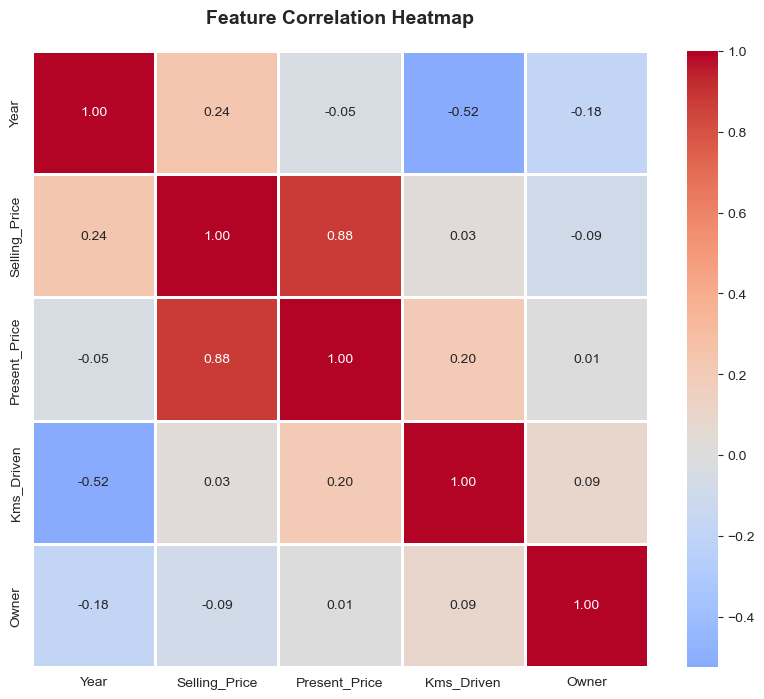

In [13]:
plt.figure(figsize=(10 , 8))
numeric_data = df.select_dtypes(include=[np.number]) # select num features
correlation = numeric_data.corr() # calcul correlation matrix
sns.heatmap(correlation, annot=True, cmap='coolwarm', center=0, square=True, linewidths=1, fmt='.2f')
plt.title('Feature Correlation Heatmap', fontsize=14, fontweight='bold', pad=20)

Text(0, 0.5, 'Selling Price (Lakhs)')

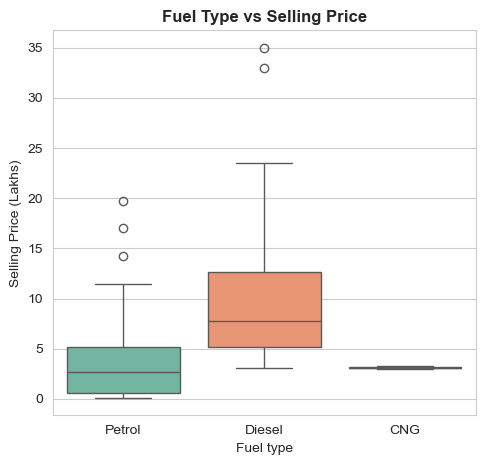

In [14]:
#Fuel type vs Selling Price
plt.figure(figsize=(12, 5))
plt.subplot(1,2,1)
sns.boxplot(x='Fuel_Type', y='Selling_Price', data=df, palette='Set2')
plt.title('Fuel Type vs Selling Price', fontweight='bold')
plt.xlabel('Fuel type')
plt.ylabel('Selling Price (Lakhs)')

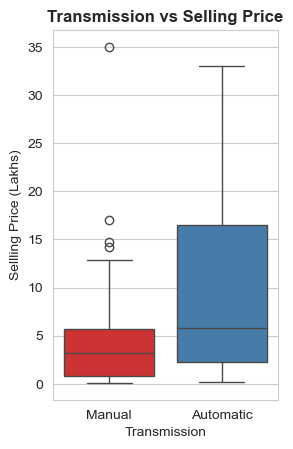

In [15]:
#Transmission vs Selling Price
plt.subplot(1,2,2)
sns.boxplot(x='Transmission', y='Selling_Price',data=df, palette='Set1')
plt.title('Transmission vs Selling Price', fontweight='bold')
plt.xlabel('Transmission')
plt.ylabel('Sellling Price (Lakhs)')
plt.show()

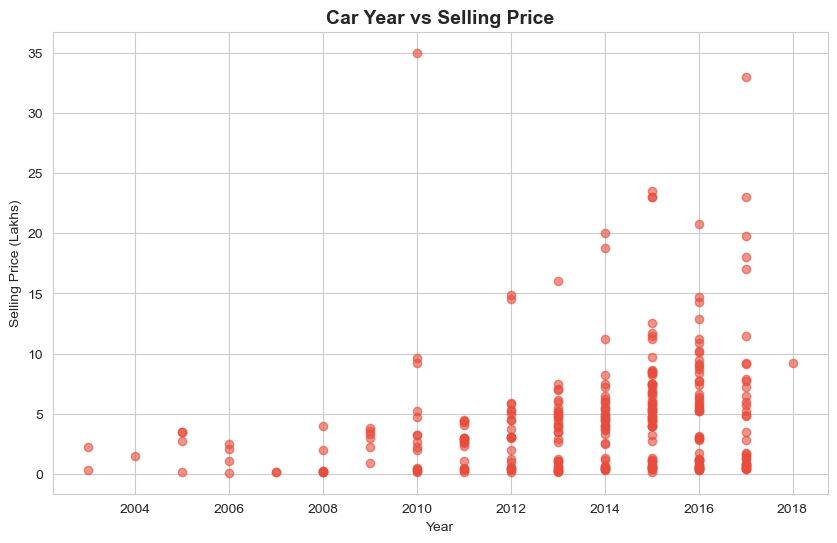

In [16]:
#Year vs Selling Price
plt.figure(figsize=(10,6))
plt.scatter(df['Year'], df['Selling_Price'], alpha=0.6, c='#e74c3c')
plt.title('Car Year vs Selling Price', fontsize=14, fontweight='bold')
plt.xlabel('Year')
plt.ylabel('Selling Price (Lakhs)')
plt.show()

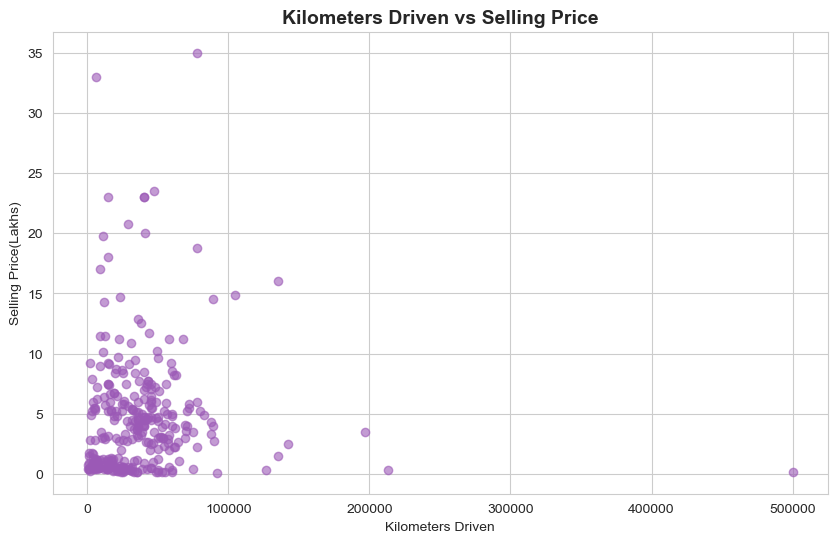

In [17]:
#Kms driven vs Selling Price

plt.figure(figsize=(10,6))
plt.scatter(df['Kms_Driven'], df['Selling_Price'], alpha=0.6, c='#9b59b6')
plt.title('Kilometers Driven vs Selling Price',fontsize=14, fontweight='bold')
plt.xlabel('Kilometers Driven')
plt.ylabel('Selling Price(Lakhs)')
plt.show()

In [18]:
#Encoding (we can use OneHoT encoding too)

df.replace({'Fuel_Type':{'Petrol':0, 'Diesel':1, 'CNG':2}}, inplace=True)
df.replace({'Seller_Type': {'Dealer':0, 'Individual':1}}, inplace= True)
df.replace({'Transmission': {'Manual':0, 'Automatic':1}}, inplace=True)

print("Encoded Dataset")
df.head() # all features now is numerical

Encoded Dataset


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,0,0,0,0
1,sx4,2013,4.75,9.54,43000,1,0,0,0
2,ciaz,2017,7.25,9.85,6900,0,0,0,0
3,wagon r,2011,2.85,4.15,5200,0,0,0,0
4,swift,2014,4.60,6.87,42450,1,0,0,0


In [19]:
# split target with features 

x =df.drop(['Car_Name','Selling_Price'],axis=1)
y = df['Selling_Price']

In [20]:
x.head()

,Year,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,2014,5.59,27000,0,0,0,0
1,2013,9.54,43000,1,0,0,0
2,2017,9.85,6900,0,0,0,0
3,2011,4.15,5200,0,0,0,0
4,2014,6.87,42450,1,0,0,0


In [21]:
y.head()

0    3.35
1    4.75
2    7.25
3    2.85
4    4.60
Name: Selling_Price, dtype: float64

In [22]:
# use train split data

In [23]:
x_train , x_test , y_train , y_test = train_test_split(x,y,test_size=0.25,random_state=2)

In [24]:
x_train.shape

(225, 7)

In [25]:
x_test.shape

(76, 7)

In [26]:
y_train.shape

(225,)

In [27]:
y_test.shape

(76,)

### modelling 

In [28]:
# model 1 : Linear regression 
#(try to find the best fit line to data that minimise distance btw target y n model)

In [42]:
lr = LinearRegression()

lr.fit(x_train,y_train)

y_train_pred_lr= lr.predict(x_train)

r2_train_lr = metrics.r2_score(y_train,y_train_pred_lr) #evalute range btw 0-1 tells us how well explains the variance

mae_train_lr = metrics.mean_absolute_error(y_train,y_train_pred_lr) #tell us the diff btw the y_prd n y_test

rmse_train_lr = metrics.mean_squared_error(y_train,y_train_pred_lr) #like mae yet it peelise the error more


In [43]:
# for train set 
print('r2_train_lr:',r2_lr)
print('mae_train_lr:',mae_lr)
print('rmse_train_lr:',rmse_lr)

r2_train_lr: 0.8340915574384854
mae_train_lr: 1.2270260204394332
rmse_train_lr: 2.713471007613188


In [44]:

lr = LinearRegression()

lr.fit(x_train,y_train)
y_pred_lr = lr.predict(x_test)

r2_lr = metrics.r2_score(y_test,y_pred_lr) #evalute range btw 0-1 tells us how well explains the variance

mae_lr = metrics.mean_absolute_error(y_test,y_pred_lr) #tell us the diff btw the y_prd n y_test

rmse_lr = metrics.mean_squared_error(y_test,y_pred_lr) #like mae yet it peelise the error more


In [45]:
# for test set 
print('r2_lr:',r2_lr)
print('mae_lr:',mae_lr)
print('rmse_lr:',rmse_lr)

r2_lr: 0.8340915574384854
mae_lr: 1.2270260204394332
rmse_lr: 2.713471007613188


Text(0.5, 1.0, 'Linear Regression - Testing')

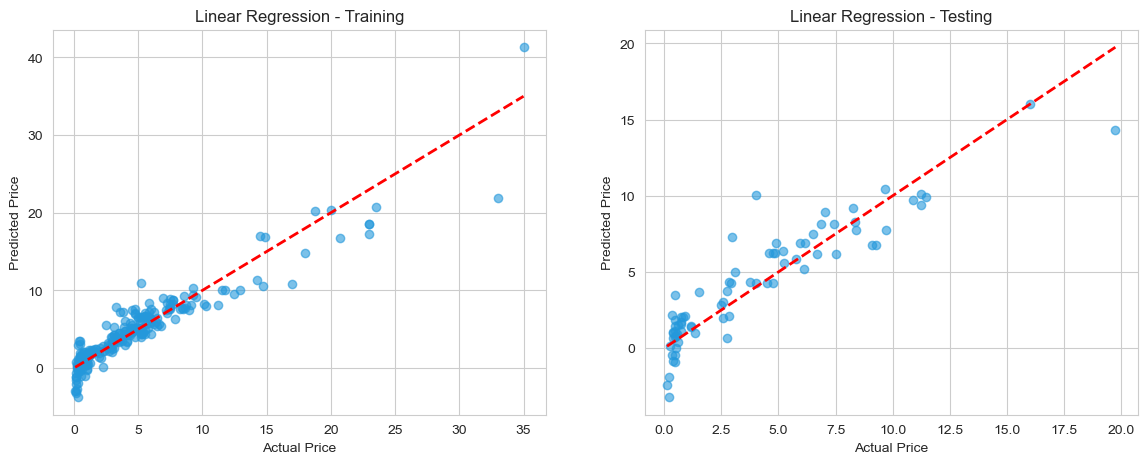

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_train, y_train_pred_lr, alpha=0.6, color='#2498db')
axes[0].plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()], 'r--', lw=2)
axes[0].set_xlabel('Actual Price')
axes[0].set_ylabel('Predicted Price')
axes[0].set_title('Linear Regression - Training')

axes[1].scatter(y_test, y_pred_lr, alpha=0.6, color='#2498db')
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[1].set_xlabel('Actual Price')
axes[1].set_ylabel('Predicted Price')
axes[1].set_title('Linear Regression - Testing')

In [48]:
# model 2 :Lasso Regression (similar to Linear regression yet it penelise the error )

In [49]:
lasso_reg = Lasso(alpha=0.1)
lasso_reg.fit(x_train, y_train)

train_pred_lasso = lasso_reg.predict(x_train)
train_r2_score = metrics.r2_score(y_train, train_pred_lasso)
train_mae_lasso = metrics.mean_absolute_error(y_train, train_pred_lasso)
train_rmse_lasso = np.sqrt(metrics.mean_squared_error(y_train, train_pred_lasso))

print('r2 score', train_r2_score)
print('mae', train_mae_lasso)
print('rmse',train_rmse_lasso)

r2 score 0.8746959632346611
mae 1.2109221539055155
rmse 1.8977996230282301


In [50]:
test_pred_lasso = lasso_reg.predict(x_test)
test_r2_score = metrics.r2_score(y_test, test_pred_lasso)
test_mae_lasso = metrics.mean_absolute_error(y_test, test_pred_lasso)
test_rmse_lasso = np.sqrt(metrics.mean_squared_error(y_test, test_pred_lasso))

print('r2 score', test_r2_score)
print('mae', test_mae_lasso)
print('rmse',test_rmse_lasso)

r2 score 0.8567054118762063
mae 1.1644335638585077
rmse 1.530887383257538


Text(0.5, 1.0, 'Lasso Regression - Testing')

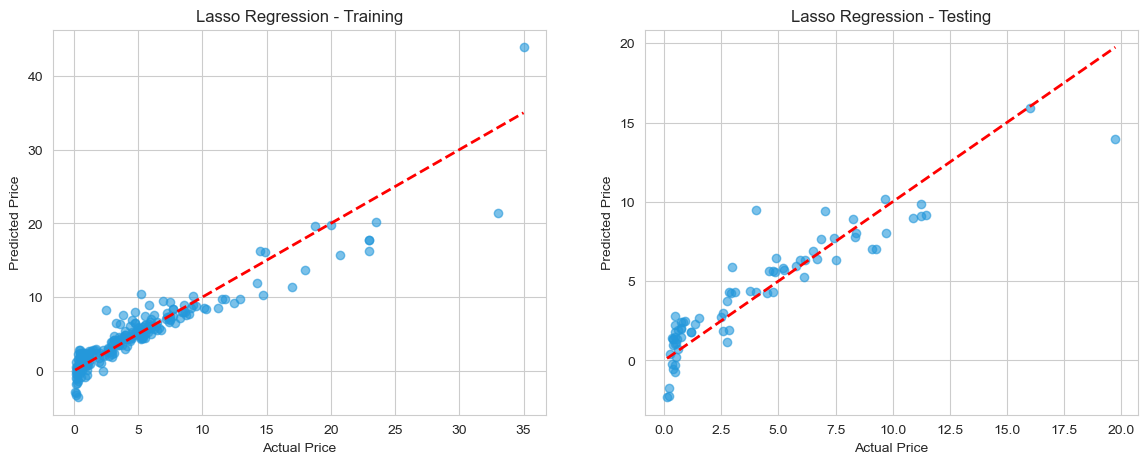

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_train, train_pred_lasso, alpha=0.6, color='#2498db')
axes[0].plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()], 'r--', lw=2)
axes[0].set_xlabel('Actual Price')
axes[0].set_ylabel('Predicted Price')
axes[0].set_title('Lasso Regression - Training')

axes[1].scatter(y_test, test_pred_lasso, alpha=0.6, color='#2498db')
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[1].set_xlabel('Actual Price')
axes[1].set_ylabel('Predicted Price')
axes[1].set_title('Lasso Regression - Testing')

In [52]:
# model 3 : Random Forest (create 100 trees)

In [53]:
rf_reg = RandomForestRegressor(n_estimators=100, random_state=2)
rf_reg.fit(x_train, y_train)

train_pred_rf = rf_reg.predict(x_train)
train_r2_rf = metrics.r2_score(y_train, train_pred_rf)
train_mae_rf = metrics.mean_absolute_error(y_train, train_pred_rf)
train_rmse_rf = np.sqrt(metrics.mean_squared_error(y_train, train_pred_rf))

print('r2 score', train_r2_rf)
print('mae', train_mae_rf)
print('rmse', train_rmse_rf)

r2 score 0.9907288541809021
mae 0.23222311111111096
rmse 0.516219648513219


In [54]:
test_pred_rf = rf_reg.predict(x_test)
test_r2_rf = metrics.r2_score(y_test, test_pred_rf)
test_mae_rf = metrics.mean_absolute_error(y_test, test_pred_rf)
test_rmse_rf = np.sqrt(metrics.mean_squared_error(y_test, test_pred_rf))

print('r2 score', test_r2_rf)
print('mae', test_mae_rf)
print('rmse', test_rmse_rf)

r2 score 0.9556923693456033
mae 0.5029026315789477
rmse 0.8512705576774175


In [55]:
# random forest tell us the most important feature
feature_importance = pd.DataFrame({
    'Feature': x.columns,
    'Importance': rf_reg.feature_importances_
}).sort_values('Importance', ascending=False)

print(feature_importance)

         Feature  Importance
1  Present_Price    0.891445
0           Year    0.078952
2     Kms_Driven    0.020105
3      Fuel_Type    0.005043
5   Transmission    0.002436
4    Seller_Type    0.001932
6          Owner    0.000087


Text(0.5, 1.0, ' Random Forest - Testing')

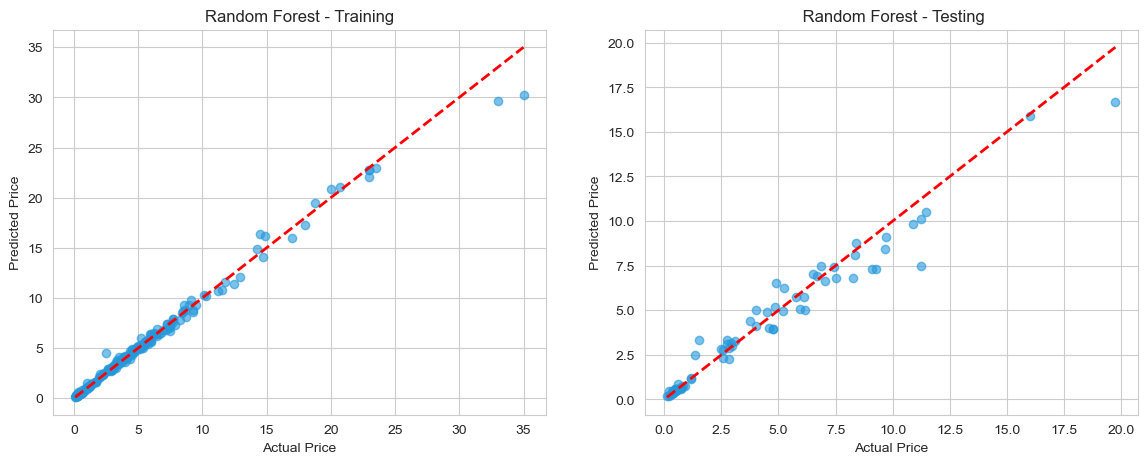

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_train, train_pred_rf, alpha=0.6, color='#2498db')
axes[0].plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()], 'r--', lw=2)
axes[0].set_xlabel('Actual Price')
axes[0].set_ylabel('Predicted Price')
axes[0].set_title('Random Forest - Training')

axes[1].scatter(y_test, test_pred_rf, alpha=0.6, color='#2498db')
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[1].set_xlabel('Actual Price')
axes[1].set_ylabel('Predicted Price')
axes[1].set_title(' Random Forest - Testing')

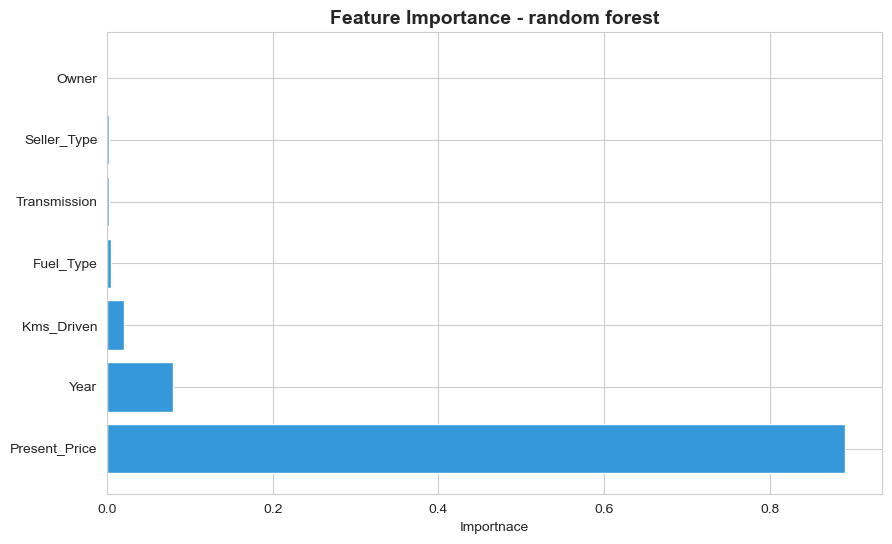

In [57]:
plt.figure(figsize=(10,6))
plt.barh(feature_importance['Feature'], feature_importance['Importance'], color ='#3498db')
plt.xlabel('Importnace')
plt.title('Feature Importance - random forest', fontsize=14, fontweight='bold')
plt.show()

In [59]:

#Model Comparison

print('Linear Regression', r2_lr)
print('Lasso Regression',test_r2_score)
print('Random Forest', test_r2_rf)

Linear Regression 0.8340915574384854
Lasso Regression 0.8567054118762063
Random Forest 0.9556923693456033


In [60]:
#Save Best Model
joblib.dump(rf_reg, 'car_prediction_model.pkl')

['car_prediction_model.pkl']

In [61]:
# test model on new exemple test
input_data = pd.DataFrame({
    'Year': [2015],
    'Present_Price': [7.0],
    'Kms_Driven': [50000],
    'Fuel_Type':[0],
    'Seller_Type':[1],
    'Transmission': [0],
    'Owner': [1]
})

prediction = rf_reg.predict(input_data)[0]
print(prediction)

4.238999999999999
